# 01 - Data preparation (CRISP-DM phases 1 to 3)

This notebook takes over `data_exploration.ipynb` of the conference paper, step by step, with the same functions (`utils_prep.py`, taken from `utils_exploration_optimised.py`). The few corrections are announced in a **Correction** box where they act.

## Outline
- [0 - Parameters](#0)
- [1 - Business understanding](#1)
- [2 - Data understanding](#2)
- [3 - Data preparation](#3)
  - [3.1 - Stop codes and type of care](#3.1)
  - [3.2 - Period](#3.2)
  - [3.3 - Missing values](#3.3)
  - [3.4 - Outliers and duplicates](#3.4)
  - [3.5 - Feature engineering](#3.5)
  - [3.6 - Feature selection and export](#3.6)
- [4 - Summary](#4)

In [1]:
import sys
sys.path.insert(0, "..")          # utils_prep.py is at the root of the repository

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")
from utils_prep import *

<a name="0"></a>
## 0 - Parameters

Every choice of this notebook is set in the cell below, with its reason. Nothing else in the notebook (or in `utils_prep.py`) changes the result.

In [2]:
# Raw consultations: the CSV of the paper (consult_waits_2024_03_25.csv), converted once
# into Parquet chunks by scripts/csv_to_parquet.py (same rows and columns, faster to read).
RAW_PARQUET_DIR = "../data/raw_data_parquet"

# eTable 1 of Feyman et al. (2022), JAMA Netw Open 5(8):e2228783: the stop codes kept, by care category.
STOP_CODES_PDF = "../references/type_stop_code.pdf"

# A well-formed row has one of these three dispositions. A few CSV lines are malformed (shifted
# columns); the paper skipped them when reading the CSV (on_bad_lines='skip').
VALID_DISP = ["COMPLETE/UPDATE", "DISCONTINUED", "CANCELLED"]

# Consultations kept: after this date, as in the paper (after the 2014 no-show peak, see 3.2).
DATE_CUTOFF = "2016-08-30 00:00:00"

# Predictors of the no-show model: the 16 variables of the paper minus the two below.
FEATURES = ["sta3n", "stopcode", "dta", "dts", "non_va", "zip", "state", "typecare",
            "day_of_week", "day_of_month", "month", "hour",
            "prior_noShow_rate", "prior_service_time_avg"]

# Variables of the paper NOT used as predictors (Correction, see 3.6): unknown when the
# appointment is booked, which is when the no-show probability is needed.
EXCLUDED_FROM_FEATURES = {
    "discontinued": "comes from the same column disp as NoShow (disposition of this consultation)",
    "service_time": "dtc - dts uses dtc, known only once this consultation is completed",
}

TARGET = "NoShow"                            # target of notebook 02
SERVICE_TIME = "service_time"                 # target of notebook 03 (dtc - dts, in days), never a predictor
OUTPUT_PATH = "../data/data_prep.parquet"   # read by notebooks 02 and 03 (patient data, not versioned)

# Row counts printed by the paper's notebook after each step, for comparison.
PAPER_ROWS = {"read": 51_861_064, "stop codes": 14_691_060, "date": 12_158_668,
              "missing values": 12_158_459, "dts <= dtc": 11_342_650, "duplicates": 11_342_613}

<a name="1"></a>
## 1 - Business understanding

- **Business objective**: minimise the average waiting time of patients and the average idle time of the clinic.
- **Data mining goal**: predict the probability that a patient does not show up, to decide which slots to overbook (notebook 03).

<a name="2"></a>
## 2 - Data understanding

One row is one consultation (a referral) of the Veterans Health Administration (VHA), from its Corporate Data Warehouse. The three delays are in **days** (Feyman et al., 2022, eFigure 1 and eTable 2 of the PDF above):
- `dta`: from the referral to its approval;
- `dts`: from the referral to the scheduling of the appointment;
- `dtc`: from the referral to the completion of the consultation.

`disp` is the disposition of the consultation: COMPLETE/UPDATE, DISCONTINUED or CANCELLED.

The stop codes kept (eTable 1 of the PDF: primary care, mental health, other specialties) are read first, because the stop-code filter of the paper (its section 3.1) is applied **while reading** the raw data, chunk by chunk. It only looks at each row, so the rows kept are the same as when filtering after loading; but only about 15 M of the 52 M rows are then held in memory (all 52 M rows do not fit in a 16 GB laptop next to the other programs).

In [3]:
primary_care_codes, mental_health_codes, all_other_specialties_codes = extract_stop_codes(STOP_CODES_PDF)
print("Primary Care Stop Codes:", primary_care_codes)
print("Mental Health Stop Codes:", mental_health_codes)
print("All Other Specialties Stop Codes:", all_other_specialties_codes)

Primary Care Stop Codes: ['322', '301', '318', '177', '348', '323']
Mental Health Stop Codes: ['502', '533', '509', '538', '510']
All Other Specialties Stop Codes: ['190', '302', '392', '317', '203', '487', '333', '391', '334', '402', '231', '303', '436', '311', '159', '160', '150', '180', '304', '106', '130', '212', '305', '369', '307']


In [4]:
data, counts, disp_all = load_raw_data(RAW_PARQUET_DIR, VALID_DISP,
                                     primary_care_codes + mental_health_codes + all_other_specialties_codes)
print(f"Rows read            : {counts['read']:,}")
print(f"Malformed rows       : {counts['malformed']:,} (dropped)")
print(f"Well-formed rows     : {counts['well-formed']:,}   (paper: {PAPER_ROWS['read']:,})")
print(f"Rows of the stop codes kept: {counts['kept']:,}   (paper: {PAPER_ROWS['stop codes']:,})")
print("\nDispositions of the well-formed rows (all stop codes):")
print(disp_all.to_string())
funnel = [("read", counts["well-formed"], disp_all["CANCELLED"] / disp_all.sum()),
          ("stop codes", counts["kept"], np.nan)]

Rows read            : 51,874,107
Malformed rows       : 13,043 (dropped)
Well-formed rows     : 51,861,064   (paper: 51,861,064)
Rows of the stop codes kept: 14,691,060   (paper: 14,691,060)

Dispositions of the well-formed rows (all stop codes):
disp
CANCELLED           1583252
COMPLETE/UPDATE    49443083
DISCONTINUED         834729


From here on, the tables and figures describe the consultations of the stop codes kept.

In [5]:
data.info(memory_usage='deep')

<class 'pandas.DataFrame'>
RangeIndex: 14691060 entries, 0 to 14691059
Data columns (total 12 columns):
 #   Column              Dtype         
---  ------              -----         
 0   patientsid          uint32        
 1   activitydatetime    datetime64[us]
 2   sta3n               int16         
 3   stopcode            int16         
 4   dta                 float32       
 5   dts                 uint16        
 6   dtc                 uint16        
 7   non_va              int8          
 8   zip                 float32       
 9   state               category      
 10  disp                category      
 11  AdministrativeFlag  category      
dtypes: category(3), datetime64[us](1), float32(2), int16(2), int8(1), uint16(2), uint32(1)
memory usage: 448.3 MB


*Numeric data summary*:

In [6]:
data[["dta", "dts", "dtc"]].describe()

,dta,dts,dtc
count,1.469106e+07,1.469106e+07,1.469106e+07
mean,3.049584e+00,1.817996e+01,3.765175e+01
std,1.087457e+01,3.169554e+01,3.816209e+01
min,0.000000e+00,0.000000e+00,0.000000e+00
25%,0.000000e+00,1.000000e+00,1.300000e+01
50%,1.000000e+00,6.000000e+00,2.700000e+01
75%,2.000000e+00,2.100000e+01,4.900000e+01
max,3.630000e+02,1.367000e+03,3.650000e+02


*Categorical data summary*:

In [7]:
data[["sta3n", "stopcode", "non_va", "zip", "state", "disp", "AdministrativeFlag"]].nunique().to_frame("distinct values")

,distinct values
sta3n,130
stopcode,36
non_va,2
zip,910
state,66
disp,3
AdministrativeFlag,2


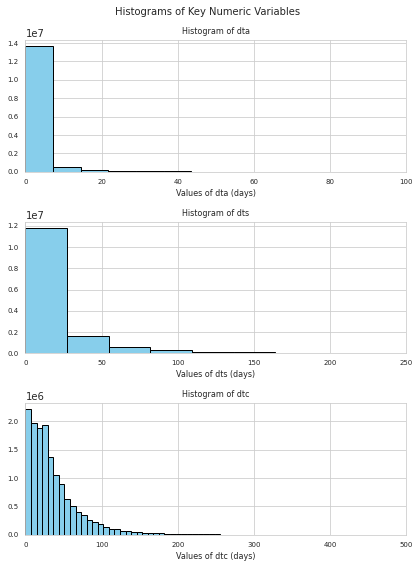

In [8]:
plot_histograms_numeric(data)

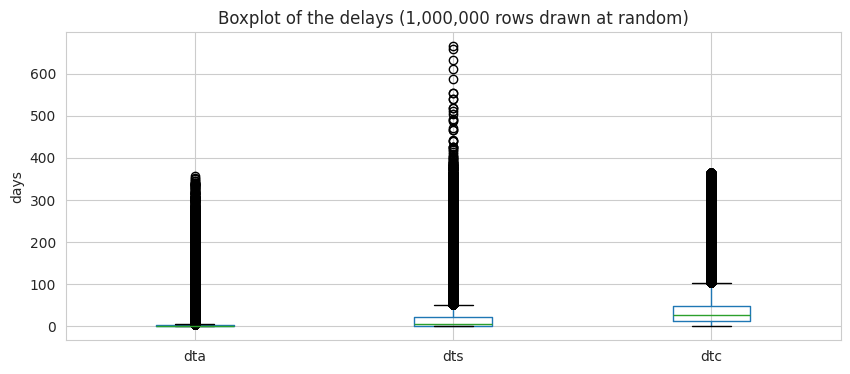

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
data[["dta", "dts", "dtc"]].sample(1_000_000, random_state=0).boxplot(ax=ax)
ax.set_ylabel("days")
plt.title('Boxplot of the delays (1,000,000 rows drawn at random)')
plt.show()

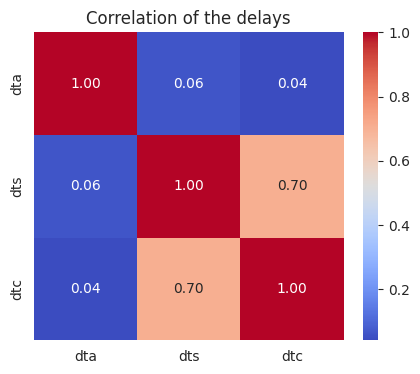

In [10]:
plt.figure(figsize=(5, 4))
sns.heatmap(data[["dta", "dts", "dtc"]].corr(), annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Correlation of the delays')
plt.show()

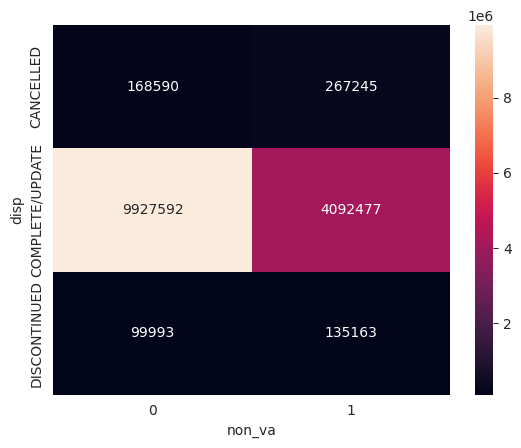

In [11]:
sns.heatmap(pd.crosstab(data['disp'], data['non_va']), annot=True, fmt='d')
plt.show()

##### Decomposing `disp` into `NoShow` and `discontinued`

As in the paper: `NoShow` = 1 if the consultation was CANCELLED, `discontinued` = 1 if it was DISCONTINUED, both 0 if it was COMPLETE/UPDATE.

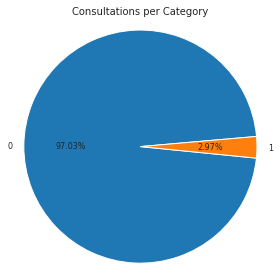

In [12]:
data = decompose_disp_column(data)
funnel[1] = ("stop codes", len(data), data[TARGET].mean())
plot_consultation_counts(data)

<a name="3"></a>
## 3 - Data preparation
<a name="3.1"></a>
### 3.1 - Stop codes and type of care

The consultations were already restricted to the stop codes of eTable 1 while reading (section 2). `typecare` = 0 for primary care, 1 for mental health and other specialties.

In [13]:
data = add_type_care(data, primary_care_codes)
print(f"Share of primary care: {(data['typecare'] == 0).mean():.4f}")

Share of primary care: 0.0806


<a name="3.2"></a>
### 3.2 - Period

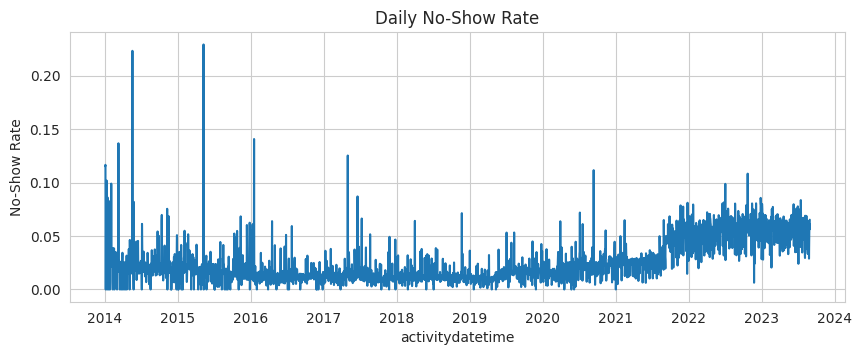

The oldest date is     : 2014-01-02 11:48:13
The most recent date is: 2023-08-30 23:57:09


In [14]:
daily_no_show = data.groupby(data['activitydatetime'].dt.date)[TARGET].mean()
daily_no_show.plot(title='Daily No-Show Rate', figsize=(10, 3.5))
plt.ylabel('No-Show Rate')
plt.show()
print("The oldest date is     :", data['activitydatetime'].min())
print("The most recent date is:", data['activitydatetime'].max())

There was a high peak in 2014, with almost 50% of no-shows, the year the Veterans Choice Program was launched in response to the waiting times of veterans. As in the paper, only the consultations after `DATE_CUTOFF` are kept, once the rate has stabilised.

Rows: 12,158,668   (paper: 12,158,668)


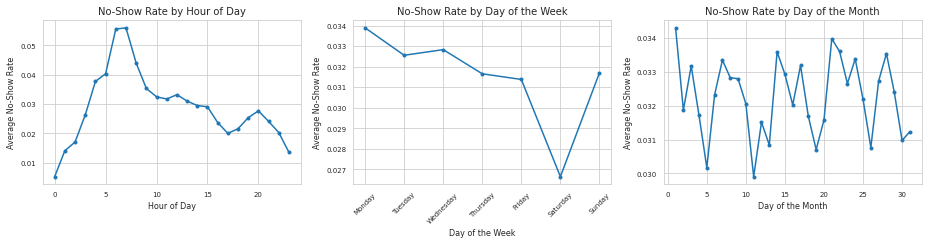

In [15]:
data = filter_dates_after(data, 'activitydatetime', DATE_CUTOFF)
data = add_temporal_features(data, 'activitydatetime')
funnel.append(("date", len(data), data[TARGET].mean()))
print(f"Rows: {len(data):,}   (paper: {PAPER_ROWS['date']:,})")
plot_patient_flow(data, TARGET)

<a name="3.3"></a>
### 3.3 - Missing values

In [16]:
display_missing_values(data)

Percentage of missing values per column:


patientsid             0.000000
activitydatetime       0.000000
sta3n                  0.000000
stopcode               0.000000
dta                    0.000000
dts                    0.000000
dtc                    0.000000
non_va                 0.000000
zip                    0.001719
state                  0.001324
AdministrativeFlag    56.864568
NoShow                 0.000000
discontinued           0.000000
typecare               0.000000
day_of_week            0.000000
day_of_month           0.000000
month                  0.000000
hour                   0.000000
dtype: float64

As in the paper: `AdministrativeFlag` is missing for more than half of the rows and is not needed, it is dropped. The few rows with a missing `zip` or `state` are deleted (listwise deletion).

In [17]:
data = data.drop(columns='AdministrativeFlag')
data = data[data['zip'].notna() & (data['state'] != '*Missing*')]
funnel.append(("missing values", len(data), data[TARGET].mean()))
print(f"Rows: {len(data):,}   (paper: {PAPER_ROWS['missing values']:,})")

Rows: 12,158,459   (paper: 12,158,459)


<a name="3.4"></a>
### 3.4 - Outliers and duplicates

A consultation cannot be completed before it is scheduled: the rows with `dts > dtc` are deleted, as in the paper. Then exact duplicates are deleted.

In [18]:
print("Number of rows where 'dts' is greater than 'dtc':", int((data['dts'] > data['dtc']).sum()))
data = data[data['dts'] <= data['dtc']]
funnel.append(("dts <= dtc", len(data), data[TARGET].mean()))

n_before = len(data)
data = data.drop_duplicates()
print(f"Number of deleted duplicates: {n_before - len(data)}")
funnel.append(("duplicates", len(data), data[TARGET].mean()))
print(f"Rows: {len(data):,}   (paper: {PAPER_ROWS['duplicates']:,})")

Number of rows where 'dts' is greater than 'dtc': 815809


Number of deleted duplicates: 37
Rows: 11,342,613   (paper: 11,342,613)


<a name="3.5"></a>
### 3.5 - Feature engineering

- `service_time` = `dtc` - `dts` (in days), as in the paper.
- The history of each patient **before** the consultation: `prior_noShow_rate` (share of no-shows among the previous consultations) and `prior_service_time_avg` (mean `service_time` of the previous consultations). They only use past consultations, so they are known when the appointment is booked.

In [19]:
data['service_time'] = data['dtc'].astype('int32') - data['dts'].astype('int32')   # int32: uint16 cannot hold a difference
data = data.drop(columns='dtc')
data = add_prior_features(data, 'patientsid', 'activitydatetime')
data[['service_time', 'prior_noShow_rate', 'prior_service_time_avg']].describe()

,service_time,prior_noShow_rate,prior_service_time_avg
count,1.134261e+07,1.134261e+07,1.134261e+07
mean,2.207162e+01,1.089245e-02,1.123435e+01
std,2.539807e+01,8.462493e-02,1.722568e+01
min,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.000000e+00,0.000000e+00,0.000000e+00
50%,1.400000e+01,0.000000e+00,2.000000e+00
75%,3.000000e+01,0.000000e+00,1.800000e+01
max,3.650000e+02,1.000000e+00,3.650000e+02


`add_prior_features` uses cumulative sums instead of the paper's `expanding()` (hours faster on 11 M rows). Check that both give the same values, on the consultations of 2,000 patients drawn at random, with the paper's code:

In [20]:
patients = pd.Series(data['patientsid'].unique()).sample(2000, random_state=0)
check = data[data['patientsid'].isin(patients)].sort_values(['patientsid', 'activitydatetime']).copy()
# Code of the paper (data_exploration.ipynb, cells 95-96)
check['cumulative_NoShow'] = check.groupby('patientsid')['NoShow'].expanding().sum().reset_index(level=0, drop=True)
check['cumulative_visits'] = check.groupby('patientsid')['NoShow'].expanding().count().reset_index(level=0, drop=True)
paper_rate = (check['cumulative_NoShow'] / check['cumulative_visits']).groupby(check['patientsid']).shift(1).fillna(0)
check['cum_st_sum'] = check.groupby('patientsid')['service_time'].expanding().sum().reset_index(level=0, drop=True)
check['cum_st_count'] = check.groupby('patientsid')['service_time'].expanding().count().reset_index(level=0, drop=True)
paper_st = (check['cum_st_sum'] / check['cum_st_count']).groupby(check['patientsid']).shift(1).fillna(0)
print(f"{len(check):,} consultations; max difference: "
      f"prior_noShow_rate {np.abs(paper_rate - check['prior_noShow_rate']).max():.2e}, "
      f"prior_service_time_avg {np.abs(paper_st - check['prior_service_time_avg']).max():.2e}")

4,258 consultations; max difference: prior_noShow_rate 0.00e+00, prior_service_time_avg 0.00e+00


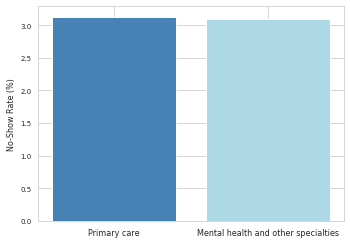

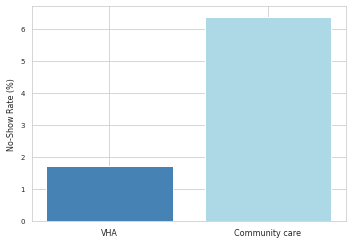

In [21]:
plot_no_show_rate_by(data, 'typecare', ['Primary care', 'Mental health and other specialties'])
plot_no_show_rate_by(data, 'non_va', ['VHA', 'Community care'])

<a name="3.6"></a>
### 3.6 - Feature selection and export

> **Correction.** The paper used 16 predictors, including `discontinued` and `service_time`. Both describe the consultation being predicted and are only known after it: `discontinued` comes from the same column `disp` as the target, and `service_time` uses `dtc`, the completion date. A model using them partly reads the answer; it cannot be applied when the appointment is booked. They are not used as predictors (`EXCLUDED_FROM_FEATURES`); `service_time` is exported only as the target of notebook 03 (groups of service time). `dta` and `dts` are kept: the referral is approved and the appointment scheduled before the consultation takes place.

In [22]:
for col, reason in EXCLUDED_FROM_FEATURES.items():
    print(f"Not a predictor: {col:<13} {reason}")
print(f"\n{len(FEATURES)} predictors:", FEATURES)

data_prep = data[FEATURES + [TARGET, SERVICE_TIME]].reset_index(drop=True)
data_prep.to_parquet(OUTPUT_PATH, index=False)
print(f"\nSaved {OUTPUT_PATH}: {data_prep.shape[0]:,} rows, {data_prep.shape[1]} columns")
data_prep.describe().T

Not a predictor: discontinued  comes from the same column disp as NoShow (disposition of this consultation)
Not a predictor: service_time  dtc - dts uses dtc, known only once this consultation is completed

14 predictors: ['sta3n', 'stopcode', 'dta', 'dts', 'non_va', 'zip', 'state', 'typecare', 'day_of_week', 'day_of_month', 'month', 'hour', 'prior_noShow_rate', 'prior_service_time_avg']



Saved ../data/data_prep.parquet: 11,342,613 rows, 16 columns


,count,mean,std,min,25%,50%,75%,max
sta3n,11342613.0,597.774844,69.009343,358.0,546.0,600.0,657.0,757.0
stopcode,11342613.0,311.288350,104.598167,106.0,301.0,304.0,323.0,538.0
dta,11342613.0,2.873959,10.662506,0.0,0.0,1.0,2.0,363.0
dts,11342613.0,16.398871,28.830793,0.0,1.0,6.0,19.0,365.0
non_va,11342613.0,0.295276,0.456167,0.0,0.0,0.0,1.0,1.0
zip,11342613.0,524.745361,274.778259,0.0,304.0,479.0,779.0,999.0
typecare,11342613.0,0.916960,0.275943,0.0,1.0,1.0,1.0,1.0
day_of_week,11342613.0,2.124780,1.486328,0.0,1.0,2.0,3.0,6.0
day_of_month,11342613.0,15.746151,8.766672,1.0,8.0,16.0,23.0,31.0
month,11342613.0,6.423385,3.401871,1.0,3.0,6.0,9.0,12.0


<a name="4"></a>
## 4 - Summary

Rows and no-show rate after each step, compared with the paper:

In [23]:
summary = pd.DataFrame(funnel, columns=["step", "rows", "no-show rate"]).set_index("step")
summary["rows in the paper"] = pd.Series(PAPER_ROWS)
summary["difference"] = summary["rows"] - summary["rows in the paper"]
summary.style.format({"rows": "{:,}", "rows in the paper": "{:,}", "difference": "{:+,}", "no-show rate": "{:.4f}"})

,rows,no-show rate,rows in the paper,difference
step,,,,
read,"51,861,064",0.0305,"51,861,064",+0
stop codes,"14,691,060",0.0297,"14,691,060",+0
date,"12,158,668",0.0323,"12,158,668",+0
missing values,"12,158,459",0.0323,"12,158,459",+0
dts <= dtc,"11,342,650",0.0311,"11,342,650",+0
duplicates,"11,342,613",0.0311,"11,342,613",+0
